## Experiment 10  Transfer Learning with ResNet18

In this experiment, we investigate whether an ImageNet-pretrained **ResNet18** can improve traffic-vehicle classification compared with the CNN models developed earlier.

Two transfer-learning strategies are compared:

1. **Feature extraction:** freeze the pretrained ResNet18 backbone and train only a new classification head for the 8 vehicle classes.
2. **Fine-tuning:** first train the new classification head while keeping the backbone frozen, then unfreeze `layer4` and the classification head and continue training with a smaller learning rate for the pretrained parameters.and then unfreeze and train the `whole layers` with a smaller learning rate.

For both experiments, the standard pretrained ResNet18 architecture is preserved. Images are resized to `224×224` and normalized using ImageNet statistics.

The experiments are evaluated using the same training/validation split and validation-based model selection used in the previous experiments. The final frozen test set is not used for model or hyperparameter selection.


In [1]:

import sys
from pathlib import Path
from torchvision import datasets
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import math
from collections import Counter
import pandas as pd

from torch.optim import Adam
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

from sklearn.metrics import classification_report

# Project root
PROJECT_DIR = Path.cwd().parent

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

sys.path.append("../src")

from data import (
    letterbox,
    create_train_val_datasets,
    create_dataloaders
)

from models import SimpleCNN

from train import train_model

from utils import (
    get_predictions,
    plot_confusion_matrix,
    get_classification_report,
    plot_training_history,
    set_seed
)

In [ ]:
SEED = 42
set_seed(SEED)

NUM_CLASSES = 8
BATCH_SIZE = 32

EPOCHS_FEATURE = 50

# EPOCHS_HEAD = 5
EPOCHS_FINETUNE = 25

HEAD_LR = 1e-3
BACKBONE_LR = 1e-4


DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu
Device: cpu


### Paths

In [8]:
MERGED_TRAIN_DIR = PROJECT_DIR / "dataset" / "merged_train"


print("Training directory:", MERGED_TRAIN_DIR)


print("Training directory exists:", MERGED_TRAIN_DIR.exists())

Training directory: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\merged_train
Training directory exists: True


### Transforms

In [9]:
imagenet_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: letterbox(
            img,
            target_size=(224, 224)
        )
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

### Create Train/Test Datasets

In [10]:
train_dataset, val_dataset, train_indices, val_indices,class_to_idx= \
    create_train_val_datasets(
        data_dir=MERGED_TRAIN_DIR,
        train_transform=imagenet_transform,
        val_transform=imagenet_transform,
        test_size=0.2,
        seed=SEED
    )


print (f"Train Dataset : {len(train_dataset)}")
print (f"Validation Dataset : {len(val_dataset)}")

Train Dataset : 2712
Validation Dataset : 679


### Class Names

In [11]:
full_dataset = datasets.ImageFolder(
    MERGED_TRAIN_DIR
)

class_names = full_dataset.classes
class_to_idx = full_dataset.class_to_idx

print("Classes:")
for index, class_name in enumerate(class_names):
    print(index, "->", class_name)

print("\nNumber of classes:", len(class_names))

Classes:
0 -> ambulance
1 -> autobus
2 -> kamyun
3 -> kamyunet
4 -> minibus
5 -> savari
6 -> taxi
7 -> vanet

Number of classes: 8


### Data Loaders

In [12]:
train_loader, val_loader = create_dataloaders(
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle_train=True
)

print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))

Number of training batches: 85
Number of validation batches: 22


### Loading the Pretrained ResNet18

We use the standard ImageNet-pretrained ResNet18 architecture.

The original convolutional stem, including `conv1` and `maxpool`, is kept unchanged so that the pretrained weights remain compatible with the architecture.

#### For the First Run:

Only the final `fully connected layer` is replaced because the original ResNet18 classifier predicts 1000 ImageNet classes, while this project contains 8 vehicle classes.


In [22]:
set_seed(SEED)
weights = ResNet18_Weights.DEFAULT

resnet_model = resnet18(weights=weights)

# Replace ImageNet's 1000-class classifier
in_features = resnet_model.fc.in_features

resnet_model.fc = nn.Linear(
    in_features,
    NUM_CLASSES
)

resnet_model = resnet_model.to(DEVICE)

In [ ]:
def count_trainable_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


def count_total_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
    )

In [25]:
print(
    "Total parameters:",
    count_total_parameters(resnet_model)
)

print(
    "Trainable parameters:",
    count_trainable_parameters(resnet_model)
)

Total parameters: 11180616
Trainable parameters: 11180616


### ResNet18 Feature Extraction

In the feature-extraction setting, the pretrained ResNet18 backbone is frozen and only the newly initialized classification head is trained.

This allows the model to use the visual features learned from ImageNet without updating the pretrained convolutional layers.

The experiment therefore tests whether the pretrained representation is already useful for distinguishing the eight vehicle classes.

### Freeze the Backbone

In [105]:
for param in resnet_model.parameters():
    param.requires_grad = False

# Train only the new classifier
for param in resnet_model.fc.parameters():
    param.requires_grad = True

print("Trainable parameters:")
print(count_trainable_parameters(resnet_model))

Trainable parameters:
4104


### Learning-rate group for Feature Extraction

In [106]:
optimizer_feature = torch.optim.Adam(
    resnet_model.fc.parameters(),
    lr=HEAD_LR,
    weight_decay=0
)

### Config 

In [107]:
config_feature = {
    "architecture": "ResNet18",
    "weights": "ImageNet pretrained",
    "strategy": "feature_extraction",
    "num_classes": NUM_CLASSES,
    "input_size": (224, 224),
    "normalization": "ImageNet",
    "optimizer": "Adam",
    "learning_rate": HEAD_LR,
    "weight_decay": 0,
    "seed": SEED,
    "trainable_layers": ["fc"]
}

In [28]:
def print_learning_rate_groups(optimizer):
    for i, group in enumerate(optimizer.param_groups):
        print(
            f"Group {i}: "
            f"LR={group['lr']}, "
            f"parameters={sum(p.numel() for p in group['params'])}"
        )

In [109]:
print_learning_rate_groups(optimizer_feature)

Group 0: LR=0.001, parameters=4104


### Train Feature Extraction Model

In [110]:
criterion = nn.CrossEntropyLoss()

history_feature, best_val_acc_feature = train_model(
    model=resnet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_feature,
    device=DEVICE,
    epochs=EPOCHS_FEATURE,
    model_name="resnet18_feature_extraction",
    class_to_idx=class_to_idx,
    seed=SEED,
    config=config_feature,
    early_stopping=True,
    patience=5,
    min_delta=0.001
)

print(
    "Best Feature Extraction Val Accuracy:",
    best_val_acc_feature
)

Epoch [1/50] Train Loss: 1.4689 --- Train Acc: 0.5195 --- Val Loss: 0.9746 --- Val Acc: 0.7216 --- LR: 0.001000
  → Validation accuracy improved. Checkpoint saved.
Epoch [2/50] Train Loss: 0.8531 --- Train Acc: 0.7607 --- Val Loss: 0.7262 --- Val Acc: 0.7968 --- LR: 0.001000
  → Validation accuracy improved. Checkpoint saved.
Epoch [3/50] Train Loss: 0.6806 --- Train Acc: 0.8119 --- Val Loss: 0.6703 --- Val Acc: 0.7997 --- LR: 0.001000
  → Validation accuracy improved. Checkpoint saved.
Epoch [4/50] Train Loss: 0.5829 --- Train Acc: 0.8355 --- Val Loss: 0.5608 --- Val Acc: 0.8321 --- LR: 0.001000
  → Validation accuracy improved. Checkpoint saved.
Epoch [5/50] Train Loss: 0.5300 --- Train Acc: 0.8466 --- Val Loss: 0.5301 --- Val Acc: 0.8292 --- LR: 0.001000
  → No improvement (1/5)
Epoch [6/50] Train Loss: 0.4838 --- Train Acc: 0.8628 --- Val Loss: 0.4915 --- Val Acc: 0.8527 --- LR: 0.001000
  → Validation accuracy improved. Checkpoint saved.
Epoch [7/50] Train Loss: 0.4584 --- Train A

In [111]:
feature_checkpoint = torch.load(
    PROJECT_DIR / "checkpoints" / "resnet18_feature_extraction_best.pt",
    map_location=DEVICE
)

resnet_model.load_state_dict(feature_checkpoint["model_state_dict"])

print("Best epoch:", feature_checkpoint["epoch"])
print("Best validation accuracy:", feature_checkpoint["val_accuracy"])

Best epoch: 11
Best validation accuracy: 0.8689248895434463


## ResNet18 Fine-Tuning

Feature extraction keeps all pretrained features fixed. In fine-tuning, we allow part of the pretrained network to adapt to the traffic-vehicle dataset.

The fine-tuning process is divided into two phases:

1. **Head training:** keep the pretrained backbone frozen and train the new classification head.
2. **Partial fine-tuning:** unfreeze `layer4` together with the classification head and continue training. A smaller learning rate is used for the pretrained `layer4` parameters, while the newly initialized head uses a larger learning rate.

Using different learning rates helps preserve useful pretrained representations while allowing the final ResNet block to adapt to the target task.


### Phase 1 : Use the Best State of the Head Training (FC Layer)

In [112]:
checkpoint = torch.load(
    PROJECT_DIR /"checkpoints"/ "resnet18_feature_extraction_best.pt",
    map_location=DEVICE
)

resnet_ft = resnet18(weights=ResNet18_Weights.DEFAULT)
resnet_ft.fc = nn.Linear(resnet_ft.fc.in_features, NUM_CLASSES)

resnet_ft.load_state_dict(checkpoint["model_state_dict"])
resnet_ft = resnet_ft.to(DEVICE)

### Phase 2 — Fine-Tuning Layer4 and the Classification Head

After training the classification head, `layer4` of ResNet18 is unfrozen.

The earlier layers remain frozen because they generally contain lower-level visual representations, while the deeper `layer4` features are more task-specific and can benefit from adaptation to the vehicle dataset.

The pretrained `layer4` parameters use a smaller learning rate than the newly initialized classification head.


In [113]:
# freeze everything
for param in resnet_ft.parameters():
    param.requires_grad = False

# unfreeze layer4
for param in resnet_ft.layer4.parameters():
    param.requires_grad = True

# keep classifier trainable
for param in resnet_ft.fc.parameters():
    param.requires_grad = True

### Two learning-rate groups

In [114]:
optimizer_ft = torch.optim.Adam(
    [
        {"params": resnet_ft.layer4.parameters(), "lr": 1e-4},
        {"params": resnet_ft.fc.parameters(), "lr": 1e-3}
    ]
)

In [115]:
print_learning_rate_groups(optimizer_ft)

Group 0: LR=0.0001, parameters=8393728
Group 1: LR=0.001, parameters=4104


### 

In [116]:
config_ft = {
    "architecture": "ResNet18",
    "weights": "ImageNet pretrained",
    "strategy": "fine_tuning",
    "num_classes": NUM_CLASSES,
    "input_size": (224, 224),
    "normalization": "ImageNet",
    "optimizer": "Adam",
    "learning_rates": {
        "layer4": BACKBONE_LR,
        "fc": HEAD_LR
    },
    "weight_decay": 0,
    "seed": SEED,
    "trainable_layers": ["layer4", "fc"]
}

### Train Fine_Tuning

In [117]:
history_ft, best_val_acc_ft = train_model(
    model=resnet_ft,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_ft,
    device=DEVICE,
    epochs=EPOCHS_FINETUNE,
    model_name="resnet18_finetuning",
    class_to_idx=class_to_idx,
    seed=SEED,
    config=config_ft,
    early_stopping=True,
    patience=5,
    min_delta=0.001
)

print(
    "Best Fine-Tuning Val Accuracy:",
    best_val_acc_ft
)

Epoch [1/25] Train Loss: 0.3127 --- Train Acc: 0.8956 --- Val Loss: 0.2901 --- Val Acc: 0.8999 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [2/25] Train Loss: 0.0419 --- Train Acc: 0.9919 --- Val Loss: 0.2624 --- Val Acc: 0.9249 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [3/25] Train Loss: 0.0110 --- Train Acc: 0.9993 --- Val Loss: 0.2502 --- Val Acc: 0.9278 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [4/25] Train Loss: 0.0053 --- Train Acc: 1.0000 --- Val Loss: 0.2473 --- Val Acc: 0.9308 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [5/25] Train Loss: 0.0030 --- Train Acc: 1.0000 --- Val Loss: 0.2439 --- Val Acc: 0.9293 --- LR: 0.000100
  → No improvement (1/5)
Epoch [6/25] Train Loss: 0.0028 --- Train Acc: 1.0000 --- Val Loss: 0.2528 --- Val Acc: 0.9337 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [7/25] Train Loss: 0.0017 --- Train A

In [118]:
ft_checkpoint = torch.load(
    PROJECT_DIR / "checkpoints" / "resnet18_finetuning_best.pt",
    map_location=DEVICE
)

resnet_ft.load_state_dict(ft_checkpoint["model_state_dict"])

print("Best epoch:", ft_checkpoint["epoch"])
print("Best validation accuracy:", ft_checkpoint["val_accuracy"])

Best epoch: 12
Best validation accuracy: 0.9396170839469808


### Compare Trainable Parameters

In [119]:
feature_trainable = sum(
    p.numel()
    for p in resnet_model.parameters()
    if p.requires_grad
)

finetune_trainable = sum(
    p.numel()
    for p in resnet_ft.parameters()
    if p.requires_grad
)

print("Feature Extraction trainable parameters:",
      feature_trainable)

print("Fine-Tuning trainable parameters:",
      finetune_trainable)

Feature Extraction trainable parameters: 4104
Fine-Tuning trainable parameters: 8397832


## Full Fine-Tuning — Training the Entire ResNet18

In this experiment, we perform **full fine-tuning** of a pretrained ResNet18 model.

Unlike feature extraction, where only the final classification head is trained, or partial fine-tuning, where only the last layers are unfrozen, here **all layers of the pretrained ResNet18 are trainable**.

The model is initialized with **ImageNet-pretrained weights**, and the final fully connected layer is replaced with a new classifier for our 8 traffic-vehicle classes.

This experiment allows us to investigate whether adapting the **entire pretrained feature extractor** to the traffic-vehicle dataset provides an improvement over feature extraction and partial fine-tuning.

The main metrics to compare are validation accuracy, macro-F1, macro precision, macro recall, and per-class performance.


In [120]:
# Load pretrained ResNet18
set_seed(SEED)
resnet_full = resnet18(weights=ResNet18_Weights.DEFAULT)

# Replace classifier
resnet_full.fc = nn.Linear(
    resnet_full.fc.in_features,
    NUM_CLASSES
)

resnet_full = resnet_full.to(DEVICE)

In [121]:
# Unfreeze All The Layers
for param in resnet_full.parameters():
    param.requires_grad = True

### Check Trainable Parameters

In [122]:
print( "Trainable parameters:", count_trainable_parameters(resnet_full) ) 
print( "Total parameters:", count_total_parameters(resnet_full) )

Trainable parameters: 11180616
Total parameters: 11180616


### Optimizer

In [123]:
# Learning rates
BACKBONE_LR = 1e-4
HEAD_LR = 1e-3


# Separate backbone and classifier parameters
backbone_params = []
head_params = []

for name, param in resnet_full.named_parameters():
    if name.startswith("fc."):
        head_params.append(param)
    else:
        backbone_params.append(param)


# Optimizer
optimizer_full = torch.optim.Adam(
    [
        {
            "params": backbone_params,
            "lr": BACKBONE_LR
        },
        {
            "params": head_params,
            "lr": HEAD_LR
        }
    ]
)

### Check learning-rate groups

In [124]:
print_learning_rate_groups(optimizer_full)

Group 0: LR=0.0001, parameters=11176512
Group 1: LR=0.001, parameters=4104


### Loss

In [125]:
criterion_full = nn.CrossEntropyLoss()

# Configuration

In [126]:
config_full = {
    "model": "ResNet18",
    "weights": "ImageNet pretrained",
    "training_mode": "full_fine_tuning",
    "optimizer": "Adam",
    "backbone_lr": BACKBONE_LR,
    "head_lr": HEAD_LR,
    "loss": "CrossEntropyLoss",
    "num_classes": NUM_CLASSES,
    "epochs": EPOCHS_FINETUNE,
    "seed": SEED
}

### Train the Full Fine Tune Model

In [127]:
history_full, best_val_acc_full = train_model(
    model=resnet_full,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_full,
    optimizer=optimizer_full,
    device=DEVICE,
    epochs=EPOCHS_FINETUNE,
    model_name="resnet18_full_finetuning",
    class_to_idx=class_to_idx,
    seed=SEED,
    config=config_full,
    scheduler=None,
    early_stopping=True,
    patience=5,
    min_delta= 0.001
)

Epoch [1/25] Train Loss: 0.5320 --- Train Acc: 0.8363 --- Val Loss: 0.1825 --- Val Acc: 0.9455 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [2/25] Train Loss: 0.0725 --- Train Acc: 0.9782 --- Val Loss: 0.1706 --- Val Acc: 0.9411 --- LR: 0.000100
  → No improvement (1/5)
Epoch [3/25] Train Loss: 0.0227 --- Train Acc: 0.9963 --- Val Loss: 0.1326 --- Val Acc: 0.9602 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [4/25] Train Loss: 0.0100 --- Train Acc: 0.9985 --- Val Loss: 0.1458 --- Val Acc: 0.9558 --- LR: 0.000100
  → No improvement (1/5)
Epoch [5/25] Train Loss: 0.0051 --- Train Acc: 0.9989 --- Val Loss: 0.1615 --- Val Acc: 0.9485 --- LR: 0.000100
  → No improvement (2/5)
Epoch [6/25] Train Loss: 0.0034 --- Train Acc: 0.9996 --- Val Loss: 0.1564 --- Val Acc: 0.9499 --- LR: 0.000100
  → No improvement (3/5)
Epoch [7/25] Train Loss: 0.0024 --- Train Acc: 0.9996 --- Val Loss: 0.1464 --- Val Acc: 0.9573 --- LR: 0.000100
  → No impro

In [128]:
# Load best checkpoint
checkpoint_full = torch.load(
    PROJECT_DIR/
    "checkpoints"/
    "resnet18_full_finetuning_best.pt",
    map_location=DEVICE
)

resnet_full.load_state_dict(
    checkpoint_full["model_state_dict"]
)

print(
    f"Best validation accuracy: "
    f"{checkpoint_full['val_accuracy']:.4f}"
)

print(
    f"Best epoch: "
    f"{checkpoint_full['epoch']}"
)

Best validation accuracy: 0.9602
Best epoch: 3


### Training Curves

Feature Extraction


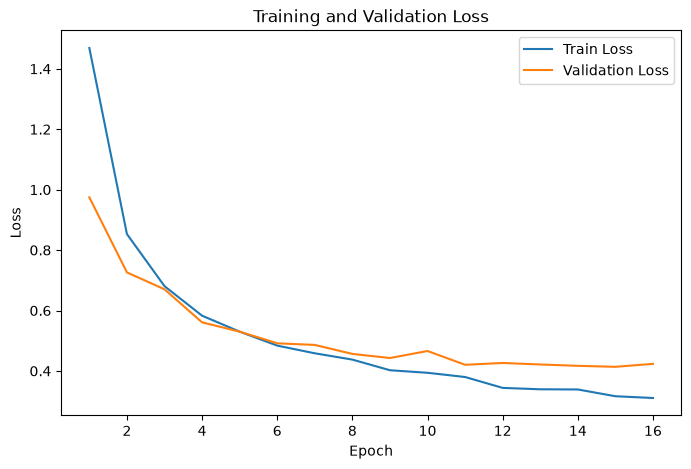

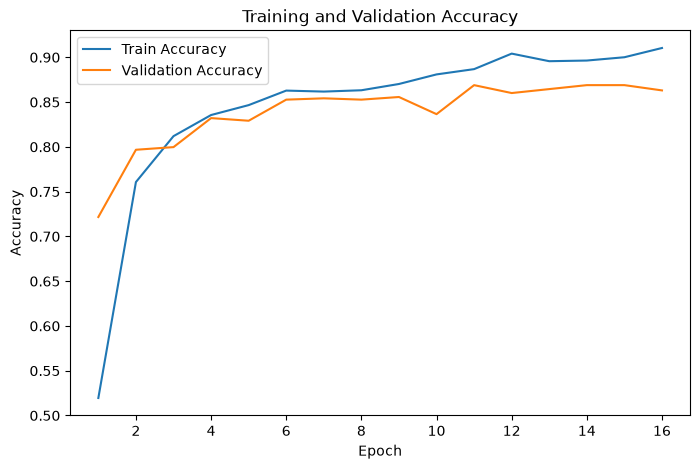

Fine-Tuning (layer4 + fc)


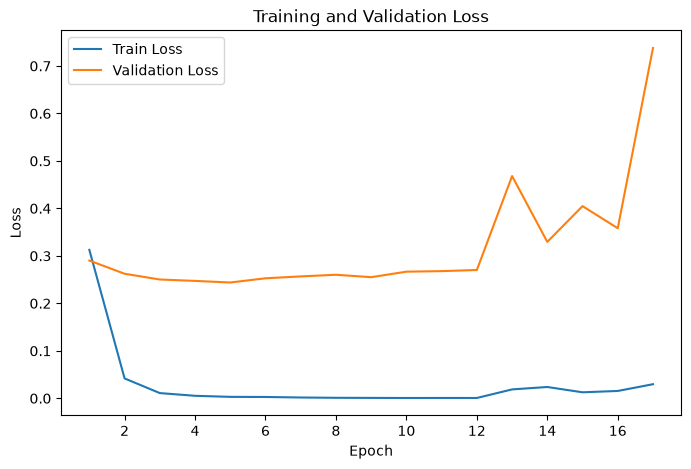

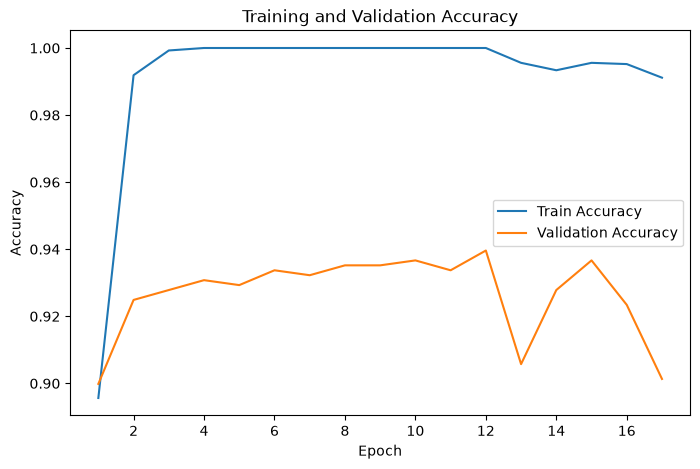

Full Fine-Tuning


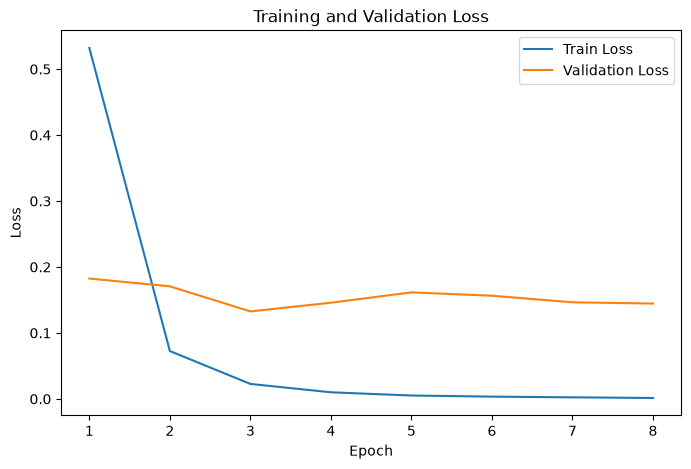

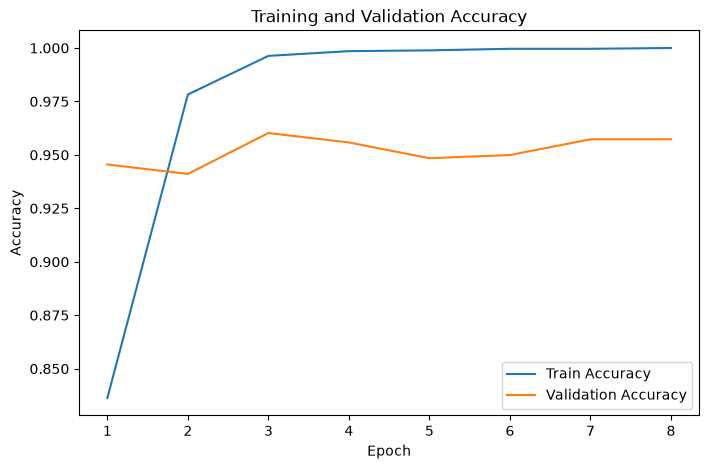

In [129]:
print("Feature Extraction")
plot_training_history(history_feature)

print("Fine-Tuning (layer4 + fc)")
plot_training_history(history_ft)

print("Full Fine-Tuning")
plot_training_history(history_full)

### Classification Report

In [130]:
print("Feature Extraction")
report_feature = get_classification_report(
    model=resnet_model,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE,
    output_dict=True
)
print(classification_report(
    *get_predictions(resnet_model, val_loader, DEVICE),
    target_names=class_names
))

print("=" * 30)
print("Fine-Tuning")
report_ft = get_classification_report(
    model=resnet_ft,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE,
    output_dict=True
)
print(classification_report(
    *get_predictions(resnet_ft, val_loader, DEVICE),
    target_names=class_names
))

print("=" * 30)
print("Full Fine-Tuning")
report_full = get_classification_report(
    model=resnet_full,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE,
    output_dict=True
)
print(classification_report(
    *get_predictions(resnet_full, val_loader, DEVICE),
    target_names=class_names
))

Feature Extraction
{'ambulance': {'precision': 0.958904109589041, 'recall': 0.9722222222222222, 'f1-score': 0.9655172413793104, 'support': 72.0}, 'autobus': {'precision': 0.9431818181818182, 'recall': 0.8829787234042553, 'f1-score': 0.9120879120879121, 'support': 94.0}, 'kamyun': {'precision': 0.8351648351648352, 'recall': 0.76, 'f1-score': 0.7958115183246073, 'support': 100.0}, 'kamyunet': {'precision': 0.8295454545454546, 'recall': 0.8021978021978022, 'f1-score': 0.8156424581005587, 'support': 91.0}, 'minibus': {'precision': 0.8202247191011236, 'recall': 0.8902439024390244, 'f1-score': 0.8538011695906432, 'support': 82.0}, 'savari': {'precision': 0.8421052631578947, 'recall': 0.96, 'f1-score': 0.897196261682243, 'support': 100.0}, 'taxi': {'precision': 0.9285714285714286, 'recall': 0.9191919191919192, 'f1-score': 0.9238578680203046, 'support': 99.0}, 'vanet': {'precision': 0.7368421052631579, 'recall': 0.6829268292682927, 'f1-score': 0.7088607594936709, 'support': 41.0}, 'accuracy': 

### Confusion Matrix

Feature Extraction


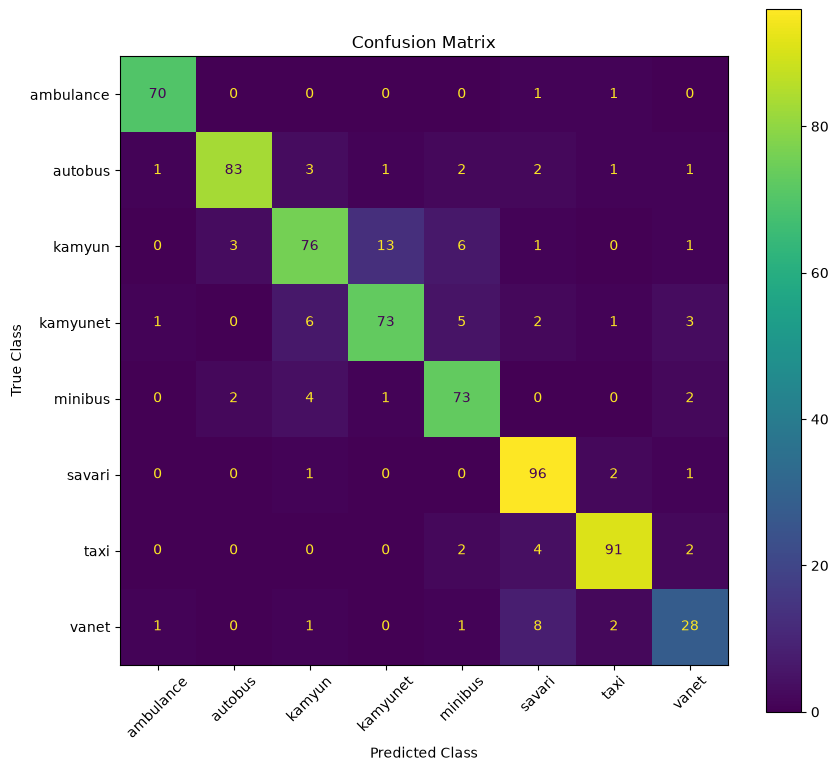

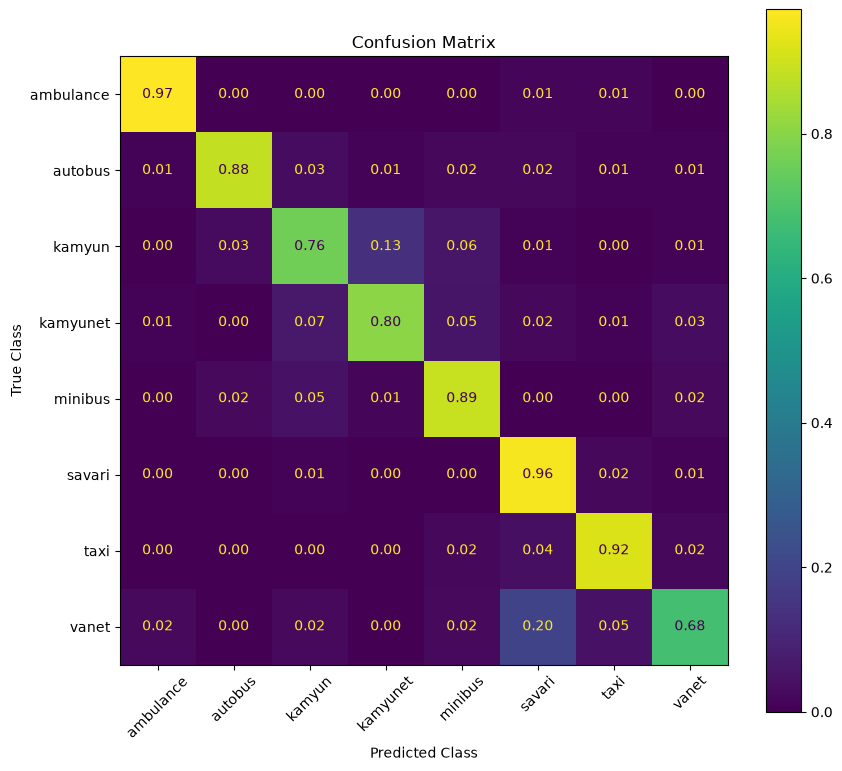

Fine-Tuning


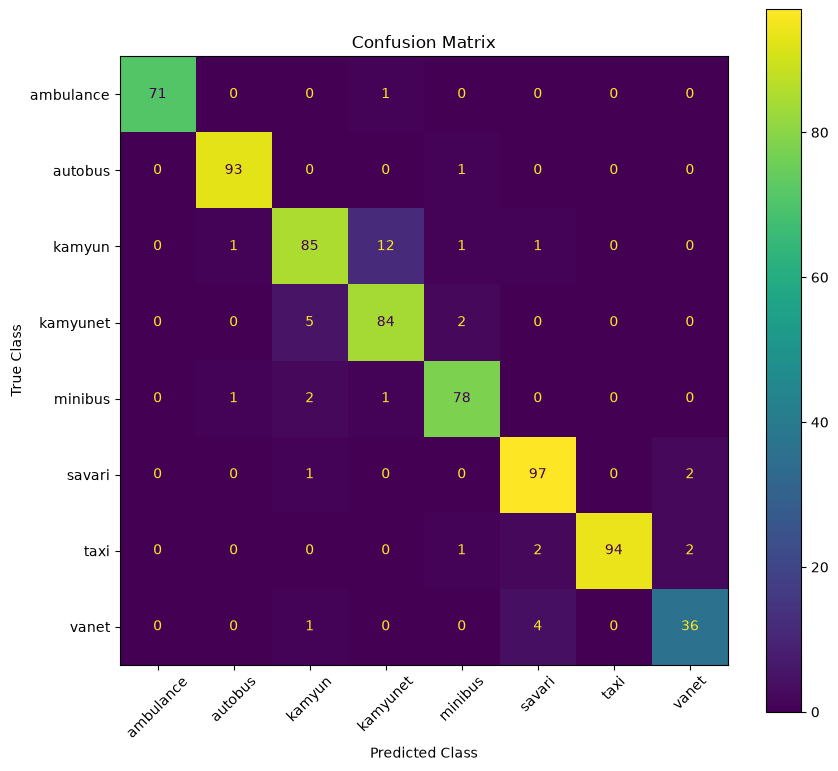

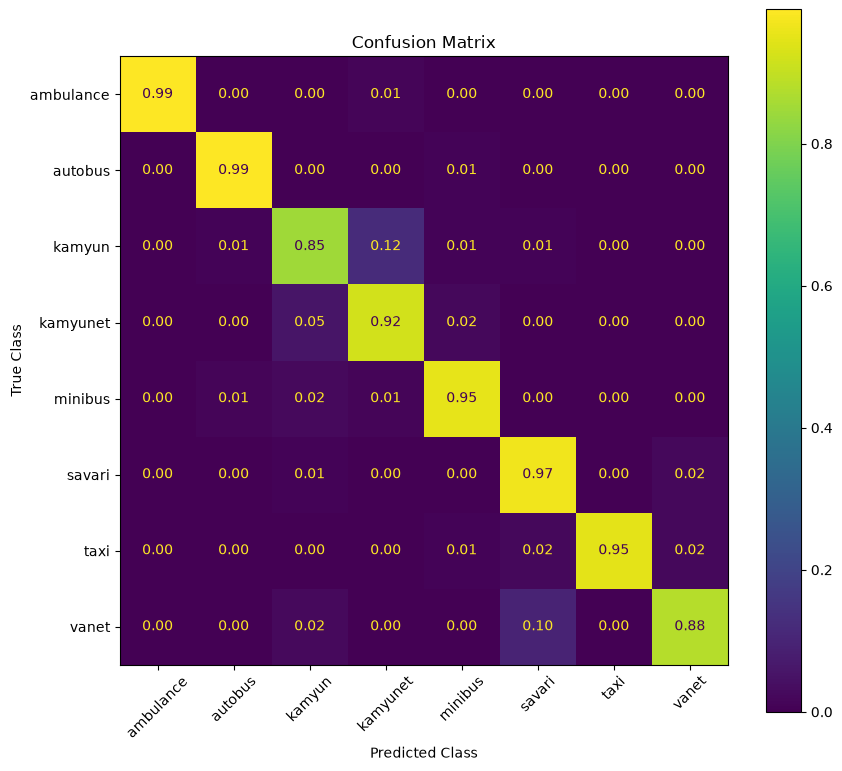

Full Fine-Tuning


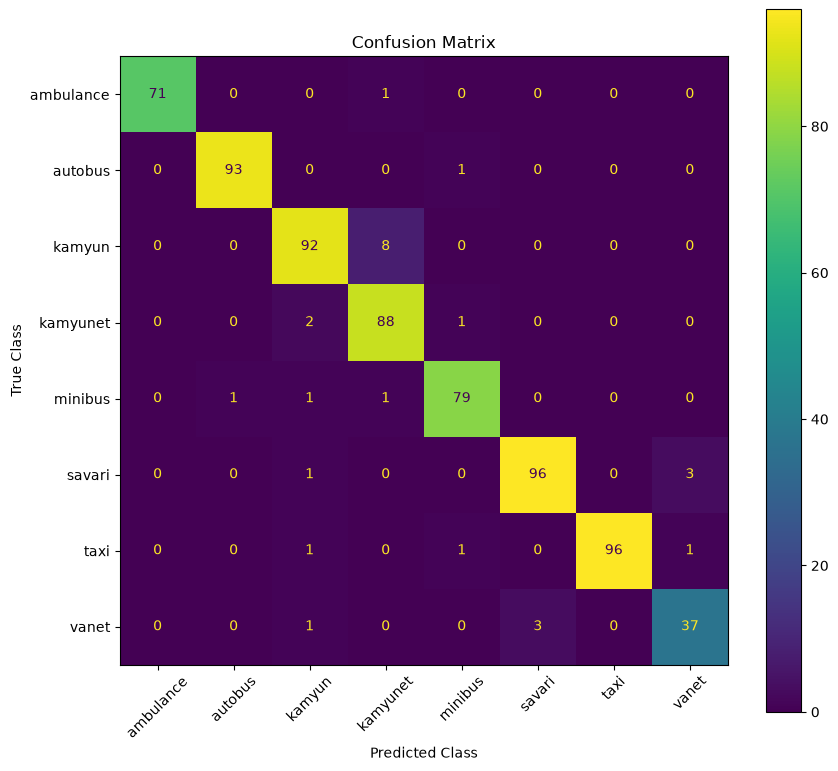

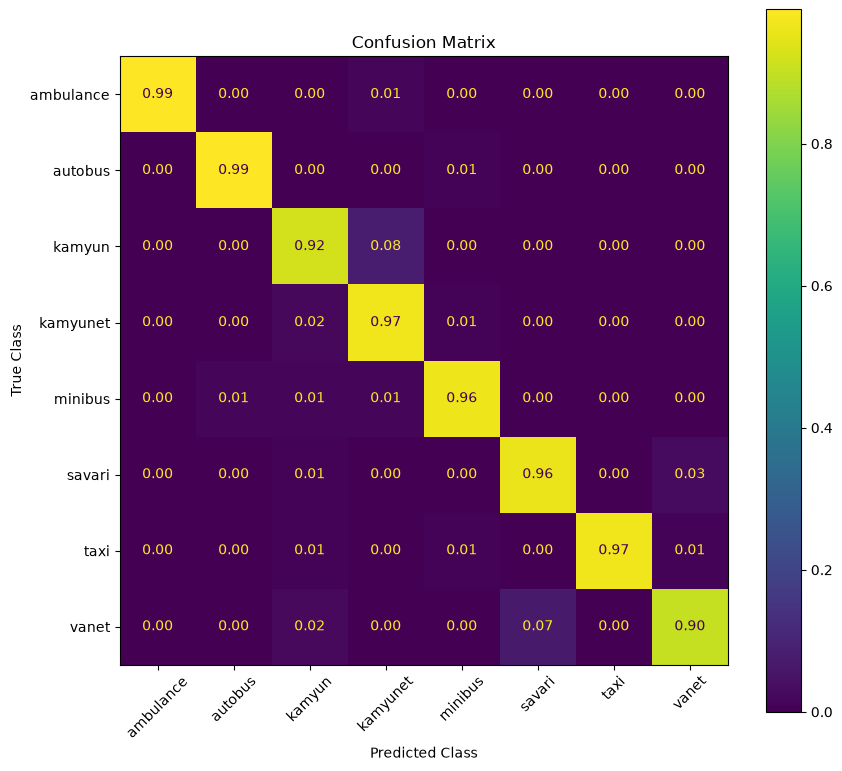

In [131]:
for name, model in [
    ("Feature Extraction", resnet_model),
    ("Fine-Tuning", resnet_ft),
    ("Full Fine-Tuning", resnet_full),
]:
    print(name)
    plot_confusion_matrix(
        model=model,
        loader=val_loader,
        class_names=class_names,
        device=DEVICE
    )
    plot_confusion_matrix(
        model=model,
        loader=val_loader,
        class_names=class_names,
        device=DEVICE,
        normalize="true"
    )

### Final Comparision

In [132]:
comparison = pd.DataFrame({
    "Feature Extraction": {
        "val_accuracy": feature_checkpoint["val_accuracy"],
        "macro_f1": report_feature["macro avg"]["f1-score"],
        "trainable_params": count_trainable_parameters(resnet_model),
    },
    "Fine-Tuning (layer4+fc)": {
        "val_accuracy": ft_checkpoint["val_accuracy"],
        "macro_f1": report_ft["macro avg"]["f1-score"],
        "trainable_params": 8397832,
    },
    "Full Fine-Tuning": {
        "val_accuracy": checkpoint_full["val_accuracy"],
        "macro_f1": report_full["macro avg"]["f1-score"],
        "trainable_params": count_trainable_parameters(resnet_full),
    },
})

comparison

,Feature Extraction,Fine-Tuning (layer4+fc),Full Fine-Tuning
val_accuracy,0.868925,9.396171e-01,9.602356e-01
macro_f1,0.859097,9.377161e-01,9.572715e-01
trainable_params,4104.000000,8.397832e+06,1.118062e+07


### Full Fine_Tune Without Data Normalization

### Transforms

In [14]:
non_norm_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: letterbox(
            img,
            target_size=(224, 224)
        )
    ),
    transforms.ToTensor(),
])

### Dataset

In [33]:
non_norm_train_dataset, non_norm_val_dataset, non_norm_train_indices, non_norm_val_indices,class_to_idx= \
    create_train_val_datasets(
        data_dir=MERGED_TRAIN_DIR,
        train_transform=non_norm_transform,
        val_transform=non_norm_transform,
        test_size=0.2,
        seed=SEED
    )


print (f"Non Norm Train Dataset : {len(non_norm_train_dataset)}")
print (f"Non Norm Validation Dataset : {len(non_norm_val_dataset)}")

Non Norm Train Dataset : 2712
Non Norm Validation Dataset : 679


### Data Loaders

In [34]:
non_norm_train_loader, non_norm_val_loader = create_dataloaders(
    train_dataset=non_norm_train_dataset,
    val_dataset=non_norm_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle_train=True
)

print("Number of training Non Norm batches:", len(non_norm_train_loader))
print("Number of validation Non Norm batches:", len(non_norm_val_loader))

Number of training Non Norm batches: 85
Number of validation Non Norm batches: 22


### Load Pretrained Weights

In [35]:
# Load pretrained ResNet18
set_seed(SEED)
non_norm_resnet_full = resnet18(weights=ResNet18_Weights.DEFAULT)

# Replace classifier
non_norm_resnet_full.fc = nn.Linear(
    resnet_full.fc.in_features,
    NUM_CLASSES
)

non_norm_resnet_full = non_norm_resnet_full.to(DEVICE)

### Unfreeze All the Layers

In [36]:
# Unfreeze All The Layers
for param in non_norm_resnet_full.parameters():
    param.requires_grad = True

### Check Trainable Parameters

In [37]:
print( "Trainable parameters:", count_trainable_parameters(non_norm_resnet_full) ) 
print( "Total parameters:", count_total_parameters(non_norm_resnet_full) )

Trainable parameters: 11180616
Total parameters: 11180616


### Optimization

In [38]:
# Learning rates
BACKBONE_LR = 1e-4
HEAD_LR = 1e-3


# Separate backbone and classifier parameters
backbone_params = []
head_params = []

for name, param in non_norm_resnet_full.named_parameters():
    if name.startswith("fc."):
        head_params.append(param)
    else:
        backbone_params.append(param)


# Optimizer
non_norm_optimizer_full = torch.optim.Adam(
    [
        {
            "params": backbone_params,
            "lr": BACKBONE_LR
        },
        {
            "params": head_params,
            "lr": HEAD_LR
        }
    ]
)

### Checlk Learning rate groups

In [41]:
print_learning_rate_groups(non_norm_optimizer_full)

Group 0: LR=0.0001, parameters=11176512
Group 1: LR=0.001, parameters=4104


### Loss

In [42]:
non_norm_criterion_full = nn.CrossEntropyLoss()

### Configuration

In [43]:
config_non_norm_full = {
    "model": "ResNet18",
    "weights": "ImageNet pretrained",
    "training_mode": "full_fine_tuning_non_normalized",
    "optimizer": "Adam",
    "backbone_lr": BACKBONE_LR,
    "head_lr": HEAD_LR,
    "loss": "CrossEntropyLoss",
    "num_classes": NUM_CLASSES,
    "epochs": EPOCHS_FINETUNE,
    "seed": SEED
}

### Train Non Normalized Model

In [44]:
history_non_norm_full, best_val_acc_non_norm_full = train_model(
    model=non_norm_resnet_full,
    train_loader=non_norm_train_loader,
    val_loader=non_norm_val_loader,
    criterion=non_norm_criterion_full,
    optimizer=non_norm_optimizer_full,
    device=DEVICE,
    epochs=EPOCHS_FINETUNE,
    model_name="resnet18_full_finetuning_non_normalized",
    class_to_idx=class_to_idx,
    seed=SEED,
    config=config_non_norm_full,
    scheduler=None,
    early_stopping=True,
    patience=5,
    min_delta= 0.001
)

Epoch [1/25] Train Loss: 0.5379 --- Train Acc: 0.8308 --- Val Loss: 0.2005 --- Val Acc: 0.9455 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [2/25] Train Loss: 0.0702 --- Train Acc: 0.9805 --- Val Loss: 0.1628 --- Val Acc: 0.9470 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [3/25] Train Loss: 0.0213 --- Train Acc: 0.9963 --- Val Loss: 0.1189 --- Val Acc: 0.9588 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [4/25] Train Loss: 0.0071 --- Train Acc: 0.9993 --- Val Loss: 0.1388 --- Val Acc: 0.9573 --- LR: 0.000100
  → No improvement (1/5)
Epoch [5/25] Train Loss: 0.0041 --- Train Acc: 0.9996 --- Val Loss: 0.1608 --- Val Acc: 0.9514 --- LR: 0.000100
  → No improvement (2/5)
Epoch [6/25] Train Loss: 0.0064 --- Train Acc: 0.9985 --- Val Loss: 0.1991 --- Val Acc: 0.9529 --- LR: 0.000100
  → No improvement (3/5)
Epoch [7/25] Train Loss: 0.0046 --- Train Acc: 0.9989 --- Val Loss: 0.1584 --- Val Acc: 0.9588 --